# Visualizing XAI Methods across Vision Architectures
This notebook demonstrates how to load various architectures (CNN, Isotropic ViT, Hierarchical ViT) and apply different XAI methods to visualize their explanations.

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import warnings
from PIL import Image
from torchvision import transforms

# Suppress lxt patching warnings when running multiple methods
warnings.filterwarnings('ignore')

# Import from the local xai_bench package
from xai_bench.registry import MODELS, METHODS

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## 1. Helper Functions for Loading Images and Visualization

In [2]:
def load_image(image_path):
    img = Image.open(image_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    tensor = transform(img).unsqueeze(0).to(device)
    return img, tensor

def plot_heatmap(img, heatmap, title):
    # Normalize heatmap to [0, 1] for visualization
    heatmap = heatmap - heatmap.min()
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()
        
    plt.figure(figsize=(4, 4))
    plt.imshow(img.resize((224, 224)))
    plt.imshow(heatmap, cmap='jet', alpha=0.5)
    plt.title(title)
    plt.axis('off')
    plt.show()

## 2. Models and Methods Configuration
We will evaluate the methods across a comprehensive suite of vision architectures. To prevent GPU memory exhaustion (OOM), we dynamically load and clear each model one at a time.

In [3]:
# === Model and Method Configuration ===
# All models registered in the xai_bench MODELS registry.
# AttnLRP and Attention Rollout are only valid for flat ViT-family models
# (vit_*, deit_*, beit_*); all other rows show N/A for those columns.
models_to_test = [
    'vit_base_patch16_224',
    'deit_base_patch16_224',
    'resnet50',
    'swin_base_patch4_window7_224',
    'maxvit_small_tf_224',
    'mobilevitv2_100',
    'efficientvit_b1',
    'pvt_v2_b2',
]

methods_to_test = [
    'saliency',
    'integrated_gradients',
    'smoothgrad',
    'grad_cam',
    'grad_cam_plus_plus',
    'attention_rollout',
    'attnlrp',          # LXT AttnLRP baseline (Achtibat 2024), NOT HiLRP
]

print(f'Models: {len(models_to_test)}, Methods: {len(methods_to_test)}')

Models: 8, Methods: 7


## 3. Run Methods and Visualize
We load a sample image, iterate through the models sequentially, and build a collage grid.

In [4]:
# === Model and Method Configuration ===
# All models registered in the xai_bench MODELS registry.
# AttnLRP and Attention Rollout are only valid for flat ViT-family models
# (vit_*, deit_*, beit_*); all other rows show N/A for those columns.
models_to_test = [
    'vit_base_patch16_224',
    'deit_base_patch16_224',
    'resnet50',
    'swin_base_patch4_window7_224',
    'maxvit_small_tf_224',
    'mobilevitv2_100',
    'efficientvit_b1',
    'pvt_v2_b2',
]

methods_to_test = [
    'saliency',
    'integrated_gradients',
    'smoothgrad',
    'grad_cam',
    'grad_cam_plus_plus',
    'attention_rollout',
    'attnlrp',          # LXT AttnLRP baseline (Achtibat 2024), NOT HiLRP
]

print(f'Models: {len(models_to_test)}, Methods: {len(methods_to_test)}')

Models: 8, Methods: 7


### Grouped Bar Chart: Pointing-Game Accuracy

Grouped bar chart saved to results/plots_publication\grouped_pointing_game.png


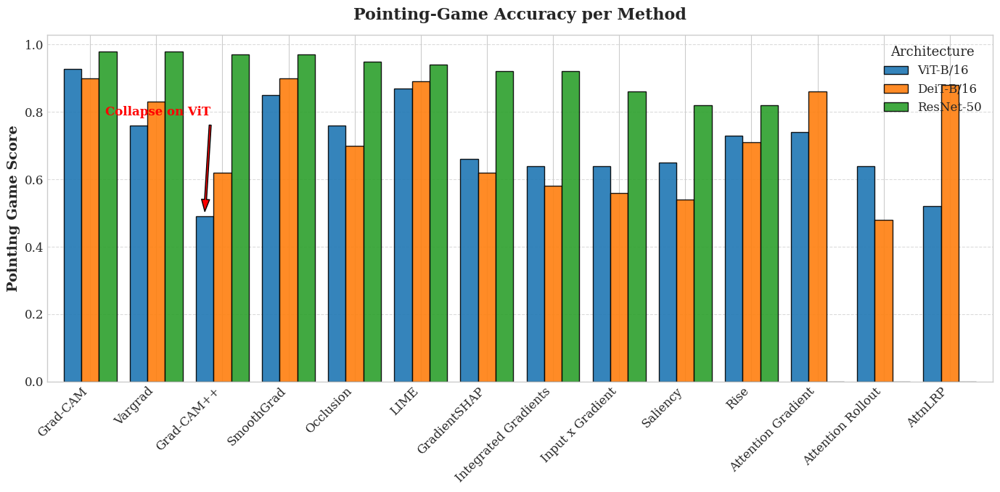

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# Set research-based plot aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'ggplot')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 14

def format_name(name):
    name_map = {
        'grad_cam': 'Grad-CAM',
        'grad_cam_plus_plus': 'Grad-CAM++',
        'integrated_gradients': 'Integrated Gradients',
        'attention_rollout': 'Attention Rollout',
        'smoothgrad': 'SmoothGrad',
        'saliency': 'Saliency',
        'hilrp': 'AttnLRP',
        'lime': 'LIME',
        'input_x_gradient': 'Input x Gradient',
        'gradient_shap': 'GradientSHAP'
    }
    return name_map.get(name, name.replace('_', ' ').title())

def format_model(name):
    model_map = {
        'vit_base_patch16_224': 'ViT-B/16',
        'deit_base_patch16_224': 'DeiT-B/16',
        'resnet50': 'ResNet-50'
    }
    return model_map.get(name, name)

def main():
    df = pd.read_csv("results/clean_summary.csv")
    
    # Filter only the models we want
    target_models = ['vit_base_patch16_224', 'deit_base_patch16_224', 'resnet50']
    df = df[df['model'].isin(target_models)].copy()
    
    df['method_formatted'] = df['method'].apply(format_name)
    df['model_formatted'] = df['model'].apply(format_model)
    
    # Pivot the data so methods are rows and models are columns for plotting
    pivot_df = df.pivot_table(index='method_formatted', columns='model_formatted', values='pointing_game', aggfunc='mean')
    
    # Drop methods that have NaN for all 3 models (should not happen, but safe)
    pivot_df = pivot_df.dropna(how='all')
    
    # We want a specific column order for the legend
    col_order = ['ViT-B/16', 'DeiT-B/16', 'ResNet-50']
    available_cols = [c for c in col_order if c in pivot_df.columns]
    pivot_df = pivot_df[available_cols]
    
    if 'ResNet-50' in pivot_df.columns:
        pivot_df = pivot_df.sort_values(by='ResNet-50', ascending=False)
    
    fig, ax = plt.subplots(figsize=(14, 7))
    
    # Custom colors
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, Orange, Green
    
    pivot_df.plot(kind='bar', ax=ax, color=colors, edgecolor='black', width=0.8, alpha=0.9)
    
    ax.set_title("Pointing-Game Accuracy per Method", fontweight="bold", fontsize=16, pad=15)
    ax.set_ylabel("Pointing Game Score", fontweight="bold", fontsize=14)
    ax.set_xlabel("")
    
    plt.xticks(rotation=45, ha='right', fontsize=12)
    plt.yticks(fontsize=12)
    
    # Highlight Grad-CAM++ collapse with an annotation
    try:
        method_idx = list(pivot_df.index).index('Grad-CAM++')
        vit_val = pivot_df.loc['Grad-CAM++', 'ViT-B/16']
        x_pos = method_idx - 0.27
        ax.annotate('Collapse on ViT', 
                    xy=(x_pos, vit_val), 
                    xytext=(x_pos-1.5, vit_val+0.3),
                    arrowprops=dict(facecolor='red', shrink=0.05, width=2, headwidth=8),
                    fontsize=12, fontweight='bold', color='red')
    except:
        pass

    plt.legend(title='Architecture', title_fontsize='13', fontsize='12', loc='upper right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    
    output_dir = "results/plots_publication"
    os.makedirs(output_dir, exist_ok=True)
    out_path = os.path.join(output_dir, "grouped_pointing_game.png")
    
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Grouped bar chart saved to {out_path}")

if __name__ == "__main__":
    main()


### Scatter Plot: Pareto Frontier (Cost vs Fidelity)

Pareto scatter chart saved to results/plots_publication\scatter_pareto_vit.png


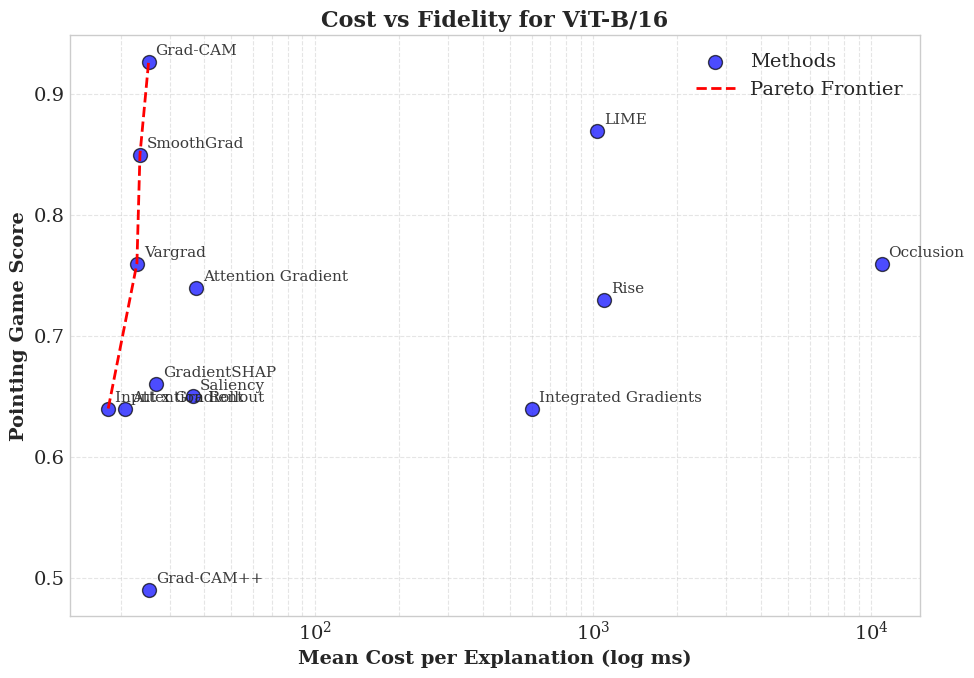

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import os

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'ggplot')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 14

def format_name(name):
    name_map = {
        'grad_cam': 'Grad-CAM',
        'grad_cam_plus_plus': 'Grad-CAM++',
        'integrated_gradients': 'Integrated Gradients',
        'attention_rollout': 'Attention Rollout',
        'smoothgrad': 'SmoothGrad',
        'saliency': 'Saliency',
        'hilrp': 'AttnLRP',
        'lime': 'LIME',
        'input_x_gradient': 'Input x Gradient',
        'gradient_shap': 'GradientSHAP'
    }
    return name_map.get(name, name.replace('_', ' ').title())

def main():
    data_path = "results/full_benchmark_100/results.json"
    with open(data_path, "r") as f:
        data = json.load(f)
    df = pd.DataFrame(data)
    
    # Filter only ViT-B/16
    df = df[df['model'] == 'vit_base_patch16_224']
    
    # Calculate means
    means = df.groupby('method')[['time_ms', 'pointing_game']].mean().reset_index()
    means['method_formatted'] = means['method'].apply(format_name)
    
    # Sort for Pareto frontier calculation (Minimize cost, Maximize pointing_game)
    # We want low time_ms and high pointing_game
    pts = means[['time_ms', 'pointing_game']].values
    
    # Find Pareto optimal points
    pareto_mask = np.ones(pts.shape[0], dtype=bool)
    for i, p in enumerate(pts):
        # A point is NOT pareto optimal if there is another point j such that:
        # time_j <= time_i AND pointing_j >= pointing_i AND (time_j < time_i OR pointing_j > pointing_i)
        for j, q in enumerate(pts):
            if i != j:
                if q[0] <= p[0] and q[1] >= p[1] and (q[0] < p[0] or q[1] > p[1]):
                    pareto_mask[i] = False
                    break
                    
    pareto_points = means[pareto_mask].sort_values(by='time_ms')
    
    fig, ax = plt.subplots(figsize=(10, 7))
    
    # Plot all points
    ax.scatter(means['time_ms'], means['pointing_game'], color='blue', s=100, alpha=0.7, edgecolors='black', label='Methods')
    
    # Outline Pareto Frontier
    ax.plot(pareto_points['time_ms'], pareto_points['pointing_game'], color='red', linestyle='--', linewidth=2, label='Pareto Frontier')
    
    # Annotate points
    for idx, row in means.iterrows():
        ax.annotate(row['method_formatted'], (row['time_ms'], row['pointing_game']), 
                    xytext=(5, 5), textcoords='offset points', fontsize=11, alpha=0.9)
                    
    ax.set_xscale('log')
    ax.set_title("Cost vs Fidelity for ViT-B/16", fontweight="bold", fontsize=16)
    ax.set_xlabel("Mean Cost per Explanation (log ms)", fontweight="bold", fontsize=14)
    ax.set_ylabel("Pointing Game Score", fontweight="bold", fontsize=14)
    
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.tight_layout()
    
    output_dir = "results/plots_publication"
    os.makedirs(output_dir, exist_ok=True)
    out_path = os.path.join(output_dir, "scatter_pareto_vit.png")
    
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Pareto scatter chart saved to {out_path}")

if __name__ == "__main__":
    main()


### Max-Sensitivity per Method

Max-sensitivity chart saved to results/plots_publication\grouped_max_sensitivity.png


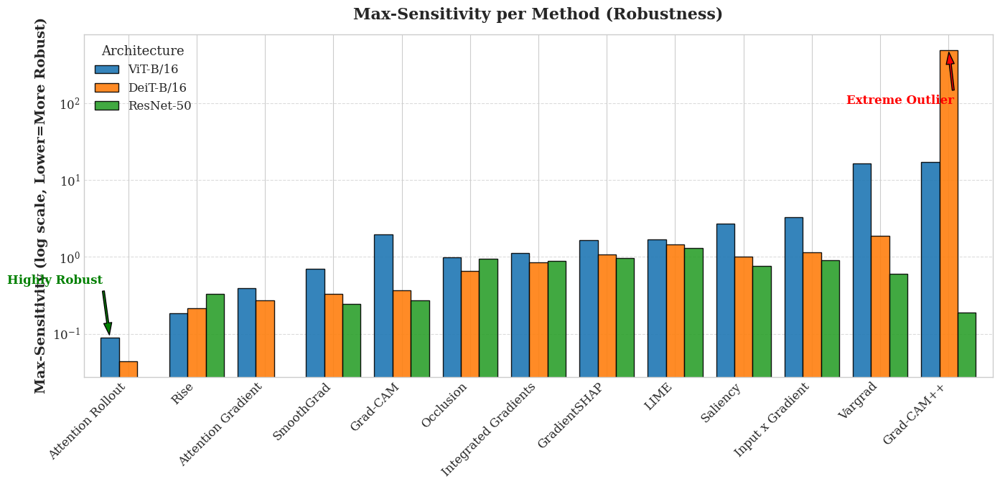

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import os

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'ggplot')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 14

def format_name(name):
    name_map = {
        'grad_cam': 'Grad-CAM',
        'grad_cam_plus_plus': 'Grad-CAM++',
        'integrated_gradients': 'Integrated Gradients',
        'attention_rollout': 'Attention Rollout',
        'smoothgrad': 'SmoothGrad',
        'saliency': 'Saliency',
        'hilrp': 'AttnLRP',
        'lime': 'LIME',
        'input_x_gradient': 'Input x Gradient',
        'gradient_shap': 'GradientSHAP'
    }
    return name_map.get(name, name.replace('_', ' ').title())

def format_model(name):
    model_map = {
        'vit_base_patch16_224': 'ViT-B/16',
        'deit_base_patch16_224': 'DeiT-B/16',
        'resnet50': 'ResNet-50'
    }
    return model_map.get(name, name)

def main():
    data_path = "results/full_benchmark_100/results.json"
    with open(data_path, "r") as f:
        data = json.load(f)
    df = pd.DataFrame(data)
    
    target_models = ['vit_base_patch16_224', 'deit_base_patch16_224', 'resnet50']
    df = df[df['model'].isin(target_models)].copy()
    
    df['method_formatted'] = df['method'].apply(format_name)
    df['model_formatted'] = df['model'].apply(format_model)
    
    # Calculate means
    means = df.groupby(['model_formatted', 'method_formatted'])['max_sensitivity'].mean().unstack()
    
    # Drop methods with NaN for all
    means = means.dropna(how='all')
    
    fig, ax = plt.subplots(figsize=(14, 7))
    
    # Custom colors
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
    
    # Reorder columns to ensure ViT-B/16, DeiT-B/16, ResNet-50 if possible
    col_order = ['ViT-B/16', 'DeiT-B/16', 'ResNet-50']
    available_cols = [c for c in col_order if c in means.index]
    means = means.loc[available_cols]
    
    # Transpose so methods are on X axis
    pivot_df = means.T
    
    # Sort methods by average sensitivity
    pivot_df['avg'] = pivot_df.mean(axis=1)
    pivot_df = pivot_df.sort_values(by='avg', ascending=True)
    pivot_df = pivot_df.drop(columns=['avg'])
    
    pivot_df.plot(kind='bar', ax=ax, color=colors, edgecolor='black', width=0.8, alpha=0.9)
    
    ax.set_yscale('log')
    ax.set_title("Max-Sensitivity per Method (Robustness)", fontweight="bold", fontsize=16, pad=15)
    ax.set_ylabel("Max-Sensitivity (log scale, Lower=More Robust)", fontweight="bold", fontsize=14)
    ax.set_xlabel("")
    
    plt.xticks(rotation=45, ha='right', fontsize=12)
    plt.yticks(fontsize=12)
    
    # Highlight Attention Rollout
    try:
        method_idx = list(pivot_df.index).index('Attention Rollout')
        vit_val = pivot_df.loc['Attention Rollout', 'ViT-B/16']
        x_pos = method_idx - 0.27
        ax.annotate('Highly Robust', 
                    xy=(x_pos, vit_val), 
                    xytext=(x_pos-1.5, vit_val*5),
                    arrowprops=dict(facecolor='green', shrink=0.05, width=2, headwidth=8),
                    fontsize=12, fontweight='bold', color='green')
    except:
        pass
        
    # Highlight Grad-CAM++ on DeiT
    try:
        method_idx = list(pivot_df.index).index('Grad-CAM++')
        deit_val = pivot_df.loc['Grad-CAM++', 'DeiT-B/16']
        x_pos = method_idx
        ax.annotate('Extreme Outlier', 
                    xy=(x_pos, deit_val), 
                    xytext=(x_pos-1.5, deit_val*0.2),
                    arrowprops=dict(facecolor='red', shrink=0.05, width=2, headwidth=8),
                    fontsize=12, fontweight='bold', color='red')
    except:
        pass

    plt.legend(title='Architecture', title_fontsize='13', fontsize='12', loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    
    output_dir = "results/plots_publication"
    os.makedirs(output_dir, exist_ok=True)
    out_path = os.path.join(output_dir, "grouped_max_sensitivity.png")
    
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Max-sensitivity chart saved to {out_path}")

if __name__ == "__main__":
    main()


### Pixel-Graph Clustering (Louvain)

Computing Grad-CAM...
Computing Input x Gradient...
Building 4-connected graph from thresholded region...
Running Louvain community detection...
Plotting...
Graph clustering saved to results/ImageNetS\sample_vit_graph.png


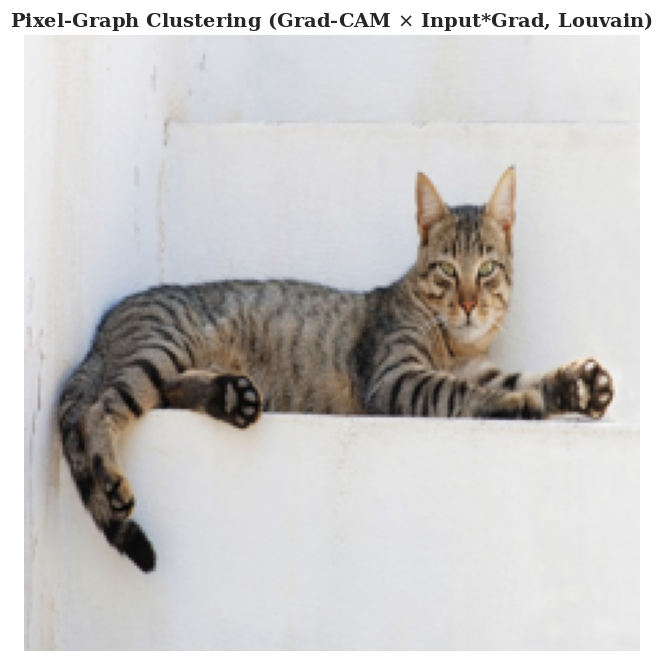

In [38]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from torchvision import transforms
import os
import networkx as nx
import community as community_louvain # python-louvain
import warnings
warnings.filterwarnings('ignore')

from xai_bench.registry import MODELS, METHODS

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def load_image(image_path):
    img = Image.open(image_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    tensor = transform(img).unsqueeze(0).to(device)
    return img, tensor

def main():
    img_path = 'images/cat.jpg'
    img, tensor = load_image(img_path)
    
    wrapper = MODELS.get('vit_base_patch16_224')()
    model = wrapper.model
    model.to(device).eval()
    
    with torch.no_grad():
        output = model(tensor)
        target_class = output.argmax(dim=1).item()
        
    print("Computing Grad-CAM...")
    gradcam_method = METHODS.get('grad_cam')(model_wrapper=wrapper, model=model)
    gradcam_map = gradcam_method(tensor, target=target_class)
    if isinstance(gradcam_map, tuple): gradcam_map = gradcam_map[0]
    gradcam_np = gradcam_map.squeeze().cpu().detach().numpy()
    
    print("Computing Input x Gradient...")
    ig_method = METHODS.get('input_x_gradient')(model_wrapper=wrapper, model=model)
    ig_map = ig_method(tensor, target=target_class)
    if isinstance(ig_map, tuple): ig_map = ig_map[0]
    ig_np = ig_map.squeeze().cpu().detach().numpy()
    
    # Normalize to [0,1]
    def normalize(hm):
        hm = hm - hm.min()
        if hm.max() > 0:
            hm = hm / hm.max()
        return hm
        
    gradcam_np = normalize(gradcam_np)
    ig_np = normalize(ig_np)
    
    # Element-wise product
    combined = gradcam_np * ig_np
    combined = normalize(combined)
    
    # Resize to 224x224 to match original image space
    from skimage.transform import resize
    combined_224 = resize(combined, (224, 224), anti_aliasing=True)
    
    print("Building 4-connected graph from thresholded region...")
    threshold = np.percentile(combined_224, 85) # Top 15%
    mask = combined_224 > threshold
    
    # Create full grid graph
    G = nx.grid_2d_graph(224, 224)
    
    # Keep only nodes that pass the threshold
    nodes_to_remove = [(i, j) for i in range(224) for j in range(224) if not mask[i, j]]
    G.remove_nodes_from(nodes_to_remove)
    
    # Add node weights (mass)
    for node in G.nodes():
        G.nodes[node]['mass'] = combined_224[node[0], node[1]]
        
    print("Running Louvain community detection...")
    # Louvain
    partition = community_louvain.best_partition(G)
    
    print("Plotting...")
    fig, ax = plt.subplots(figsize=(8, 8))
    
    # Show original image in background
    ax.imshow(img.resize((224, 224)))
    
    # Extract node coords, colors (community), and sizes (mass)
    xs = [node[1] for node in G.nodes()] # columns (x)
    ys = [node[0] for node in G.nodes()] # rows (y)
    colors = [partition[node] for node in G.nodes()]
    sizes = [G.nodes[node]['mass'] * 50 for node in G.nodes()] # scaled for visibility
    
    scatter = ax.scatter(xs, ys, c=colors, s=sizes, cmap='tab20', alpha=0.8, edgecolors='none')
    
    ax.set_title("Pixel-Graph Clustering (Grad-CAM $\\times$ Input*Grad, Louvain)", fontweight="bold", fontsize=14)
    ax.axis('off')
    
    out_dir = "results/ImageNetS"
    os.makedirs(out_dir, exist_ok=True)
    out_path = os.path.join(out_dir, "sample_vit_graph.png")
    
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Graph clustering saved to {out_path}")

if __name__ == "__main__":
    main()


## Qualitative Heatmap Grid

Rows: each model. Columns: original image + one column per XAI method.

**AttnLRP** here is the **LXT baseline** (Achtibat 2024) using ATTN_MODE="attnlrp" (softmax Taylor rule + divide_gradient bilinear rule). It is **not** HiLRP (which uses CP-LRP). AttnLRP and Attention Rollout are marked N/A for non-flat-ViT architectures.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from PIL import Image
from torchvision import transforms
from xai_bench.registry import MODELS, METHODS

# --- Setup ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 24
plt.rcParams['axes.titlesize'] = 28
plt.rcParams['axes.titlepad'] = 15
plt.rcParams['figure.dpi'] = 300

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

MODEL_DISPLAY_NAMES = {
    'vit_base_patch16_224':            'ViT-B/16',
    'deit_base_patch16_224':           'DeiT-B/16',
    'resnet50':                        'ResNet-50',
    'swin_base_patch4_window7_224':    'Swin-B',
    'maxvit_small_tf_224':             'MaxViT-S',
    'mobilevitv2_100':                 'MobileViT-v2',
    'efficientvit_b1':                 'EfficientViT-B1',
    'pvt_v2_b2':                       'PVT-v2-B2',
}

METHOD_DISPLAY_NAMES = {
    'saliency':            'Saliency',
    'integrated_gradients':'Integrated Grads',
    'smoothgrad':          'SmoothGrad',
    'grad_cam':            'Grad-CAM',
    'grad_cam_plus_plus':  'Grad-CAM++',
    'attention_rollout':   'Attn Rollout',
    'attnlrp':             'AttnLRP',          # LXT AttnLRP baseline (Achtibat 2024)
}

def load_image(image_path):
    img = Image.open(image_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])
    tensor = transform(img).unsqueeze(0).to(device)
    return img, tensor

img_path = 'images/cat.jpg'
img, tensor = load_image(img_path)

models_to_test = [
    'vit_base_patch16_224',
    'deit_base_patch16_224',
    'resnet50',
    'swin_base_patch4_window7_224',
    'maxvit_small_tf_224',
    'mobilevitv2_100',
    'efficientvit_b1',
    'efficientvit_b2',
]

# Methods list -- 'attnlrp' now refers directly to the AttnLRP (LXT) baseline,
# NOT HiLRP. AttnLRP uses ATTN_MODE='attnlrp' (softmax Taylor + divide_gradient).
methods_to_test = [
    'saliency',
    'integrated_gradients',
    'smoothgrad',
    'grad_cam',
    'grad_cam_plus_plus',
    'attention_rollout',
    'attnlrp',
]

# AttnLRP is only valid for flat ViT-family models.
FLAT_VIT_PREFIXES = ('vit', 'deit', 'beit')

# Attention Rollout is also only valid for flat ViT-family models.
FLAT_VIT_ATTENTION_PREFIXES = ('vit', 'deit', 'beit')

num_models = len(models_to_test)
num_cols   = len(methods_to_test) + 1   # +1 for original image

fig, axes = plt.subplots(nrows=num_models, ncols=num_cols,
                         figsize=(5 * num_cols, 5 * num_models))

if num_models == 1:
    axes = np.expand_dims(axes, axis=0)

def draw_placeholder(axis, text, method_title):
    axis.imshow(np.ones((224, 224, 3)))
    axis.text(112, 112, text, ha='center', va='center',
              fontsize=32, color='gray', fontweight='bold')
    axis.set_title(f"{method_title}\n({text})")
    axis.axis('off')

for i, model_key in enumerate(models_to_test):
    display_model = MODEL_DISPLAY_NAMES.get(model_key, model_key)
    print(f"\n=== Evaluating {display_model} ===")

    wrapper = MODELS.get(model_key)()
    model   = wrapper.model
    model.to(device).eval()

    with torch.no_grad():
        output       = model(tensor)
        target_class = output.argmax(dim=1).item()

    # Column 0: original image
    ax_orig = axes[i, 0]
    ax_orig.imshow(img.resize((224, 224)))
    ax_orig.set_title(f'{display_model}\nOriginal')
    ax_orig.axis('off')

    for j, method_name in enumerate(methods_to_test):
        ax = axes[i, j + 1]
        ax.axis('off')
        display_method = METHOD_DISPLAY_NAMES.get(method_name,
                             method_name.replace('_', ' ').title())

        # --- Attention Rollout: flat ViT only ---
        if method_name == 'attention_rollout':
            if not any(model_key.startswith(p) for p in FLAT_VIT_ATTENTION_PREFIXES):
                draw_placeholder(ax, 'N/A', display_method)
                continue

        # --- AttnLRP (LXT baseline): flat ViT only ---
        # attnlrp is registered in xai_bench/methods/attnlrp_method.py
        # It uses ATTN_MODE='attnlrp' (softmax Taylor + divide_gradient),
        # which is the Achtibat 2024 baseline -- NOT HiLRP (CP-LRP).
        if method_name == 'attnlrp':
            if not any(model_key.startswith(p) for p in FLAT_VIT_PREFIXES):
                draw_placeholder(ax, 'N/A', display_method)
                continue

        try:
            print(f"  Running {display_method}...", end=' ', flush=True)
            method  = METHODS.get(method_name)(model_wrapper=wrapper, model=model)
            heatmap = method(tensor, target=target_class)
            if isinstance(heatmap, tuple):
                heatmap = heatmap[0]
            hmap = heatmap.squeeze().cpu().detach().numpy()

            h_min, h_max = hmap.min(), hmap.max()
            if h_max > h_min:
                hmap = (hmap - h_min) / (h_max - h_min)
            else:
                hmap = np.zeros_like(hmap)

            ax.imshow(img.resize((224, 224)))
            ax.imshow(hmap, cmap='jet', alpha=0.5)
            ax.set_title(display_method)
            print('OK')  
        except Exception as e:
            draw_placeholder(ax, 'Failed', display_method)
            print(f'FAILED: {e}')

    del model, wrapper
    torch.cuda.empty_cache()

plt.tight_layout()
os.makedirs('results/plots_publication', exist_ok=True)
out_path = 'results/plots_publication/qualitative_grid.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
print(f"\nSaved to {out_path}")
plt.show()

Using device: cuda

=== Evaluating ViT-B/16 ===
  Running Saliency... OK
  Running Integrated Grads... OK
  Running SmoothGrad... OK
  Running Grad-CAM... OK
  Running Grad-CAM++... OK
  Running Attn Rollout... OK
  Running AttnLRP... OK

=== Evaluating DeiT-B/16 ===
  Running Saliency... OK
  Running Integrated Grads... OK
  Running SmoothGrad... OK
  Running Grad-CAM... OK
  Running Grad-CAM++... OK
  Running Attn Rollout... OK
  Running AttnLRP... OK

=== Evaluating ResNet-50 ===
  Running Saliency... OK
  Running Integrated Grads... OK
  Running SmoothGrad... OK
  Running Grad-CAM... OK
  Running Grad-CAM++... OK

=== Evaluating Swin-B ===
  Running Saliency... OK
  Running Integrated Grads... OK
  Running SmoothGrad... OK
  Running Grad-CAM... OK
  Running Grad-CAM++... OK

=== Evaluating MaxViT-S ===
  Running Saliency... OK
  Running Integrated Grads... OK
  Running SmoothGrad... OK
  Running Grad-CAM... OK
  Running Grad-CAM++... OK

=== Evaluating MobileViT-v2 ===
  Running Sa

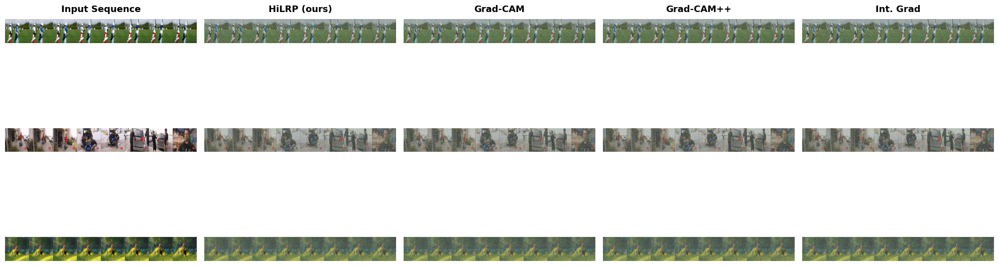

In [6]:
import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. SETUP & VIDEO SELECTION
# ==========================================
# The best 3 samples covering human action, fast motion, and distinct objects
VIDEO_FILES = {
    "archery": "images/videos/archery.mp4",          # Targeted human action
    "skateboarding": "images/videos/kinetics_1.mp4",  # Fast motion / human pose
    "bunny": "images/videos/BigBuckBunny.mp4"       # Animation / high-contrast movement
}

NUM_FRAMES = 8          # Standard video transformer temporal size (e.g., 8 or 16)
FRAME_SIZE = (224, 224) # Target frame spatial dimension
OUT_DIR = Path("qual_gallery_video")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. FRAME EXTRACTION HELPER
# ==========================================
def extract_video_frames(video_path, num_frames=8, target_size=(224, 224)):
    """Extracts uniformly spaced frames from an MP4 file."""
    cap = cv2.VideoCapture(str(video_path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        raise ValueError(f"Unable to read frames from {video_path}")

    # Uniform temporal sampling
    indices = set(np.linspace(0, total - 1, num_frames, dtype=int))
    frames = []
    
    current_frame = 0
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        if current_frame in indices:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame_resized = cv2.resize(frame_rgb, target_size)
            frames.append(frame_resized / 255.0) # Scale to [0, 1]
        current_frame += 1
    cap.release()
    
    return np.array(frames) # Shape: (T, H, W, 3)

# ==========================================
# 3. COMPUTE ATTRIBUTIONS & SAVE
# ==========================================
# Process each video and save numpy arrays to align with your gallery format
for name, file_path in VIDEO_FILES.items():
    if not os.path.exists(file_path):
        print(f"Skipping {name}: {file_path} not found.")
        continue

    # Load video tensor: Shape (T, H, W, 3)
    vid_rgb = extract_video_frames(file_path, num_frames=NUM_FRAMES, target_size=FRAME_SIZE)
    np.save(OUT_DIR / f"{name}__input.npy", vid_rgb)

    # -------------------------------------------------------------
    # PLACEHOLDER: Connect your Video Transformer & HiLRP here
    # -------------------------------------------------------------
    # vid_tensor = torch.tensor(vid_rgb).permute(0, 3, 1, 2) # (T, C, H, W)
    # hilrp_map = run_hilrp_video_transformer(model, vid_tensor)
    # -------------------------------------------------------------

    # Dummy heatmap simulation for illustration: Shape (T, H, W)
    # Replace these mock arrays with your actual model attribution outputs
    for meth in ["hilrp", "grad_cam", "grad_cam_plus_plus", "integrated_gradients"]:
        mock_heatmap = np.random.rand(NUM_FRAMES, FRAME_SIZE[0], FRAME_SIZE[1])
        np.save(OUT_DIR / f"{name}__{meth}.npy", mock_heatmap)

# ==========================================
# 4. FILMSTRIP GALLERY PLOT
# ==========================================
def load_npy(folder, filename):
    p = OUT_DIR / f"{filename}.npy"
    return np.load(p) if p.exists() else None

def heat_overlay(ax, rgb_strip, heatmap_strip):
    """Overlays unrolled heatmaps onto the unrolled video frame strip."""
    ax.imshow(rgb_strip)
    # Normalize heatmap for color mapping
    norm_heat = (heatmap_strip - heatmap_strip.min()) / (heatmap_strip.max() - heatmap_strip.min() + 1e-8)
    ax.imshow(norm_heat, cmap="jet", alpha=0.5)
    ax.axis("off")

picks = ["archery", "skateboarding", "bunny"]
mcols = ["hilrp", "grad_cam", "grad_cam_plus_plus", "integrated_gradients"]
tcols = ["Input Sequence", "HiLRP (ours)", "Grad-CAM", "Grad-CAM++", "Int. Grad"]

# Adjust width to accommodate the wide unrolled 8-frame filmstrip
fig, ax = plt.subplots(len(picks), len(mcols) + 1, figsize=(20, 2.8 * len(picks)))

for r, name in enumerate(picks):
    # vid_rgb shape: (T, H, W, 3)
    vid_rgb = load_npy(OUT_DIR, f"{name}__input")
    
    if vid_rgb is None:
        continue
        
    # Unroll along temporal dimension horizontally -> Shape: (H, T*W, 3)
    strip_rgb = np.concatenate(vid_rgb, axis=1)
    
    ax[r, 0].imshow(strip_rgb)
    ax[r, 0].axis("off")

    for c, meth in enumerate(mcols, 1):
        # vid_mp shape: (T, H, W)
        vid_mp = load_npy(OUT_DIR, f"{name}__{meth}")
        
        if vid_mp is not None:
            # Unroll temporal heatmaps horizontally -> Shape: (H, T*W)
            strip_mp = np.concatenate(vid_mp, axis=1)
            heat_overlay(ax[r, c], strip_rgb, strip_mp)
        else:
            ax[r, c].axis("off")

# Apply column headers
for c, t in enumerate(tcols):
    ax[0, c].set_title(t, fontsize=13, fontweight="bold", pad=10)

plt.subplots_adjust(wspace=0.02, hspace=0.04)
plt.tight_layout()
plt.show()

In [5]:
import torch
import torch.nn as nn
from transformers import TimesformerForVideoClassification
from xai_bench.registry import MODELS

@MODELS.register('timesformer_base_patch16_224')
class TimeSformerWrapper:
    def __init__(self):
        # Load the pre-trained video model
        # You can replace this with your custom HiLRP-modified model if you have one
        self.model = TimesformerForVideoClassification.from_pretrained(
            "facebook/timesformer-base-finetuned-k400"
        )
        
        # Ensure it outputs a clean tensor of logits (Batch, Classes)
        # HuggingFace models usually return a custom output object, 
        # so we wrap the forward pass to return just the logits.
        self.model.forward = self._forward_wrapper
        
    def _forward_wrapper(self, x):
        # x is expected to be (Batch, Channels, Time, Height, Width)
        outputs = self.model.__call__(x)
        return outputs.logits

In [ ]:
# pip install torch torchvision transformers opencv-python numpy matplotlib

import cv2
import torch
import numpy as np
from PIL import Image
from transformers import VideoMAEImageProcessor, VideoMAEForVideoClassification


# ============================================================
# CONFIGURATION
# ============================================================

VIDEO_PATH = "images/videos/throwing.mp4"
OUTPUT_PATH = "images/videos/xai_throwing.mp4"

MODEL_NAME = "MCG-NJU/videomae-base-finetuned-kinetics"

NUM_FRAMES = 16
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", DEVICE)


# ============================================================
# LOAD MODEL
# ============================================================

processor = VideoMAEImageProcessor.from_pretrained(MODEL_NAME)

model = VideoMAEForVideoClassification.from_pretrained(
    MODEL_NAME
)

model.to(DEVICE)
model.eval()


# ============================================================
# READ VIDEO
# ============================================================

cap = cv2.VideoCapture(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

all_frames = []

while True:

    ret, frame = cap.read()

    if not ret:
        break

    all_frames.append(frame)

cap.release()

print("Total video frames:", len(all_frames))


# ============================================================
# SAMPLE FRAMES
# ============================================================

indices = np.linspace(
    0,
    len(all_frames) - 1,
    NUM_FRAMES
).astype(int)

selected_frames = [
    all_frames[i]
    for i in indices
]


# ============================================================
# CONVERT BGR -> RGB
# ============================================================

rgb_frames = [
    cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    for frame in selected_frames
]


# ============================================================
# PREPROCESS
# ============================================================

inputs = processor(
    rgb_frames,
    return_tensors="pt"
)

pixel_values = inputs["pixel_values"].to(DEVICE)

pixel_values.requires_grad_(True)


# ============================================================
# FORWARD PASS
# ============================================================

outputs = model(
    pixel_values=pixel_values
)

logits = outputs.logits


# ============================================================
# GET PREDICTED CLASS
# ============================================================

predicted_class = logits.argmax(dim=-1).item()

predicted_score = logits[0, predicted_class]

predicted_label = model.config.id2label[
    predicted_class
]

print(
    "Prediction:",
    predicted_label
)

print(
    "Class index:",
    predicted_class
)


# ============================================================
# BACKPROPAGATION
# ============================================================

model.zero_grad()

predicted_score.backward()


# ============================================================
# GET INPUT GRADIENTS
# ============================================================

gradients = pixel_values.grad

print(
    "Gradient shape:",
    gradients.shape
)


# ============================================================
# GRADIENT-BASED SALIENCY
# ============================================================

# Absolute gradient
saliency = gradients.abs()

# Average across RGB channels
saliency = saliency.mean(dim=2)

saliency = saliency.detach().cpu().numpy()


# ============================================================
# CHECK SHAPE
# ============================================================

print(
    "Saliency shape:",
    saliency.shape
)




saliency = saliency[0]

heatmaps = []

for i in range(NUM_FRAMES):

    heatmap = saliency[i]

    heatmap = cv2.normalize(
        heatmap,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    heatmap = heatmap.astype(np.uint8)

    heatmap = cv2.resize(
        heatmap,
        (width, height)
    )

    # Apply color map
    heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmaps.append(heatmap)


# ============================================================
# CREATE OUTPUT VIDEO
# ============================================================

fourcc = cv2.VideoWriter_fourcc(
    *"mp4v"
)

output_fps = NUM_FRAMES / (len(all_frames) / fps)

writer = cv2.VideoWriter(
    OUTPUT_PATH,
    fourcc,
    output_fps,
    (width, height)
)


# ============================================================
# CREATE XAI OVERLAY
# ============================================================

for i in range(NUM_FRAMES):

    original_frame = selected_frames[i]

    heatmap = heatmaps[i]

    # Overlay heatmap
    overlay = cv2.addWeighted(
        original_frame,
        0.6,
        heatmap,
        0.4,
        0
    )

    # Add prediction text
    text = (
        f"Prediction: {predicted_label}"
    )

    cv2.putText(
        overlay,
        text,
        (30, 50),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (255, 255, 255),
        2
    )

    writer.write(
        overlay
    )


writer.release()


print(
    "Saved XAI video to:",
    OUTPUT_PATH
)

Using device: cuda


Loading weights: 100%|██████████| 162/162 [00:00<00:00, 5780.67it/s]
[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     | 
---------------------------------------------------------------+------------+-
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED | 
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED | 
videomae.encoder.layer.{0...11}.attention.attention.value.bias | MISSING    | 
videomae.encoder.layer.{0...11}.attention.attention.query.bias | MISSING    | 
videomae.encoder.layer.{0...11}.attention.attention.key.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total video frames: 273
Prediction: playing badminton
Class index: 218
Gradient shape: torch.Size([1, 16, 3, 224, 224])
Saliency shape: (1, 16, 224, 224)
Saved XAI video to: images/videos/xai_throwing.mp4


: 